# Week 4: Invoice Late Payment Prediction - Classification Models

In [ ]:
import pandas as pd

df = pd.read_csv("clean_invoice_data (1).csv")

df.head()

,business_code,cust_number,name_customer,clear_date,buisness_year,doc_id,posting_date,document_create_date,document_create_date.1,due_in_date,...,area_business,total_open_amount,baseline_create_date,cust_payment_terms,invoice_id,isopen,days_to_pay,delay,paid_late_flag,open_paid_flag
0,U001,0200769623,WAL-MAR corp,2020-02-11,2020.0,1.930438e+09,2020-01-26,20200125,20200126,1970-01-01 00:00:00.020200210,...,NaN,54273.28,1970-01-01 00:00:00.020200126,NAH4,1.930438e+09,0,16.0,18302.0,1,Paid
1,U001,0200980828,BEN E,2019-08-08,2019.0,1.929646e+09,2019-07-22,20190722,20190722,1970-01-01 00:00:00.020190811,...,NaN,79656.60,1970-01-01 00:00:00.020190722,NAD1,1.929646e+09,0,17.0,18115.0,1,Paid
2,U001,0200792734,MDV/ trust,2019-12-30,2019.0,1.929874e+09,2019-09-14,20190914,20190914,1970-01-01 00:00:00.020190929,...,NaN,2253.86,1970-01-01 00:00:00.020190914,NAA8,1.929874e+09,0,107.0,18259.0,1,Paid
3,CA02,0140105686,SYSC llc,NaN,2020.0,2.960623e+09,2020-03-30,20200330,20200330,1970-01-01 00:00:00.020200410,...,NaN,3299.70,1970-01-01 00:00:00.020200331,CA10,2.960623e+09,1,NaN,NaN,0,Open
4,U001,0200769623,WAL-MAR foundation,2019-11-25,2019.0,1.930148e+09,2019-11-13,20191113,20191113,1970-01-01 00:00:00.020191128,...,NaN,33133.29,1970-01-01 00:00:00.020191113,NAH4,1.930148e+09,0,12.0,18224.0,1,Paid


In [ ]:
import os

os.getcwd()

'/content'

In [ ]:
os.listdir("/content")

['.config', 'clean_invoice_data (1).csv', 'sample_data']

In [ ]:
import pandas as pd

df = pd.read_csv("/content/clean_invoice_data (1).csv")

df.head()

,business_code,cust_number,name_customer,clear_date,buisness_year,doc_id,posting_date,document_create_date,document_create_date.1,due_in_date,...,area_business,total_open_amount,baseline_create_date,cust_payment_terms,invoice_id,isopen,days_to_pay,delay,paid_late_flag,open_paid_flag
0,U001,0200769623,WAL-MAR corp,2020-02-11,2020.0,1.930438e+09,2020-01-26,20200125,20200126,1970-01-01 00:00:00.020200210,...,NaN,54273.28,1970-01-01 00:00:00.020200126,NAH4,1.930438e+09,0,16.0,18302.0,1,Paid
1,U001,0200980828,BEN E,2019-08-08,2019.0,1.929646e+09,2019-07-22,20190722,20190722,1970-01-01 00:00:00.020190811,...,NaN,79656.60,1970-01-01 00:00:00.020190722,NAD1,1.929646e+09,0,17.0,18115.0,1,Paid
2,U001,0200792734,MDV/ trust,2019-12-30,2019.0,1.929874e+09,2019-09-14,20190914,20190914,1970-01-01 00:00:00.020190929,...,NaN,2253.86,1970-01-01 00:00:00.020190914,NAA8,1.929874e+09,0,107.0,18259.0,1,Paid
3,CA02,0140105686,SYSC llc,NaN,2020.0,2.960623e+09,2020-03-30,20200330,20200330,1970-01-01 00:00:00.020200410,...,NaN,3299.70,1970-01-01 00:00:00.020200331,CA10,2.960623e+09,1,NaN,NaN,0,Open
4,U001,0200769623,WAL-MAR foundation,2019-11-25,2019.0,1.930148e+09,2019-11-13,20191113,20191113,1970-01-01 00:00:00.020191128,...,NaN,33133.29,1970-01-01 00:00:00.020191113,NAH4,1.930148e+09,0,12.0,18224.0,1,Paid


In [ ]:
df.shape

(48839, 23)

In [ ]:
df.columns


Index(['business_code', 'cust_number', 'name_customer', 'clear_date',
       'buisness_year', 'doc_id', 'posting_date', 'document_create_date',
       'document_create_date.1', 'due_in_date', 'invoice_currency',
       'document_type', 'posting_id', 'area_business', 'total_open_amount',
       'baseline_create_date', 'cust_payment_terms', 'invoice_id', 'isopen',
       'days_to_pay', 'delay', 'paid_late_flag', 'open_paid_flag'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48839 entries, 0 to 48838
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   business_code           48839 non-null  object 
 1   cust_number             48839 non-null  object 
 2   name_customer           48839 non-null  object 
 3   clear_date              39158 non-null  object 
 4   buisness_year           48839 non-null  float64
 5   doc_id                  48839 non-null  float64
 6   posting_date            48839 non-null  object 
 7   document_create_date    48839 non-null  int64  
 8   document_create_date.1  48839 non-null  int64  
 9   due_in_date             48839 non-null  object 
 10  invoice_currency        48839 non-null  object 
 11  document_type           48839 non-null  object 
 12  posting_id              48839 non-null  float64
 13  area_business           0 non-null      float64
 14  total_open_amount       48839 non-null

In [ ]:
df['paid_late_flag'].value_counts()

,count
paid_late_flag,
1,39158
0,9681


In [ ]:
X = df.drop(
    ['paid_late_flag', 'days_to_pay', 'delay'],
    axis=1
)

y = df['paid_late_flag']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (48839, 20)
Target: (48839,)


In [ ]:
X = X.drop(
    [
        'doc_id',
        'invoice_id',
        'name_customer',
        'cust_number',
        'area_business'
    ],
    axis=1
)

X.shape

(48839, 15)

In [ ]:
X.columns

Index(['business_code', 'clear_date', 'buisness_year', 'posting_date',
       'document_create_date', 'document_create_date.1', 'due_in_date',
       'invoice_currency', 'document_type', 'posting_id', 'total_open_amount',
       'baseline_create_date', 'cust_payment_terms', 'isopen',
       'open_paid_flag'],
      dtype='object')

In [ ]:
df[['clear_date','posting_date','due_in_date','baseline_create_date']].head()

,clear_date,posting_date,due_in_date,baseline_create_date
0,2020-02-11,2020-01-26,1970-01-01 00:00:00.020200210,1970-01-01 00:00:00.020200126
1,2019-08-08,2019-07-22,1970-01-01 00:00:00.020190811,1970-01-01 00:00:00.020190722
2,2019-12-30,2019-09-14,1970-01-01 00:00:00.020190929,1970-01-01 00:00:00.020190914
3,NaN,2020-03-30,1970-01-01 00:00:00.020200410,1970-01-01 00:00:00.020200331
4,2019-11-25,2019-11-13,1970-01-01 00:00:00.020191128,1970-01-01 00:00:00.020191113


In [ ]:
df['open_paid_flag'].value_counts()

,count
open_paid_flag,
Paid,39158
Open,9681


In [ ]:
X = X.drop(
    [
        'clear_date',
        'posting_date',
        'due_in_date',
        'baseline_create_date',
        'document_create_date',
        'document_create_date.1',
        'open_paid_flag'
    ],
    axis=1
)

X.shape

(48839, 8)

In [ ]:
X.columns

Index(['business_code', 'buisness_year', 'invoice_currency', 'document_type',
       'posting_id', 'total_open_amount', 'cust_payment_terms', 'isopen'],
      dtype='object')

In [ ]:
numeric_features = [
    'buisness_year',
    'posting_id',
    'total_open_amount',
    'isopen'
]

categorical_features = [
    'business_code',
    'invoice_currency',
    'document_type',
    'cust_payment_terms'
]

print("Numerical Columns:", numeric_features)
print("Categorical Columns:", categorical_features)

Numerical Columns: ['buisness_year', 'posting_id', 'total_open_amount', 'isopen']
Categorical Columns: ['business_code', 'invoice_currency', 'document_type', 'cust_payment_terms']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (39071, 8)
X_test: (9768, 8)
y_train: (39071,)
y_test: (9768,)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully")

Preprocessing Pipeline Created Successfully


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully")

Logistic Regression Model Trained Successfully


In [ ]:
y_pred = logistic_model.predict(X_test)

y_pred[:10]

array([1, 1, 1, 1, 1, 1, 0, 0, 0, 1])

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1936
           1       1.00      1.00      1.00      7832

    accuracy                           1.00      9768
   macro avg       1.00      1.00      1.00      9768
weighted avg       1.00      1.00      1.00      9768



In [ ]:
pd.crosstab(df['isopen'], df['paid_late_flag'])

paid_late_flag,0,1
isopen,,
0,0,39158
1,9681,0


In [ ]:
df[['isopen','paid_late_flag']].head(10)

,isopen,paid_late_flag
0,0,1
1,0,1
2,0,1
3,1,0
4,0,1
5,0,1
6,0,1
7,1,0
8,0,1
9,0,1


In [ ]:
X = X.drop(['isopen'], axis=1)

X.shape

(48839, 7)

In [ ]:
numeric_features = [
    'buisness_year',
    'posting_id',
    'total_open_amount'
]

categorical_features = [
    'business_code',
    'invoice_currency',
    'document_type',
    'cust_payment_terms'
]

print("Numerical Columns:", numeric_features)
print("Categorical Columns:", categorical_features)

Numerical Columns: ['buisness_year', 'posting_id', 'total_open_amount']
Categorical Columns: ['business_code', 'invoice_currency', 'document_type', 'cust_payment_terms']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (39071, 7)
X_test: (9768, 7)
y_train: (39071,)
y_test: (9768,)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully")

Preprocessing Pipeline Created Successfully


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully")

Logistic Regression Model Trained Successfully


In [ ]:
y_pred = logistic_model.predict(X_test)

y_pred[:10]

array([1, 1, 1, 1, 0, 1, 0, 0, 0, 1])

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8902538902538902
Precision: 0.9907084785133565
Recall: 0.8712972420837589
F1 Score: 0.9271739130434783

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.97      0.78      1936
           1       0.99      0.87      0.93      7832

    accuracy                           0.89      9768
   macro avg       0.82      0.92      0.85      9768
weighted avg       0.92      0.89      0.90      9768



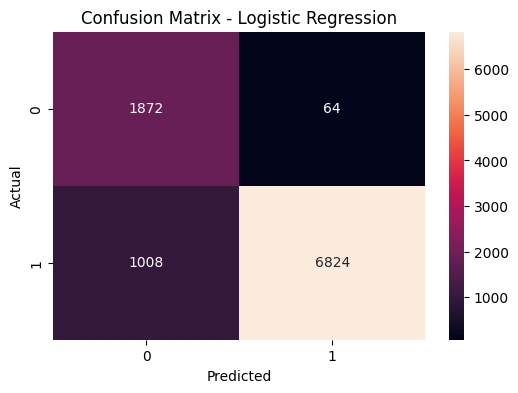

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully")

Random Forest Model Trained Successfully


In [ ]:
rf_pred = rf_model.predict(X_test)

rf_pred[:10]

array([1, 1, 1, 1, 0, 1, 1, 0, 1, 1])

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Accuracy: 0.8657862407862408
Precision: 0.9220711974110032
Recall: 0.9094739530132788
F1 Score: 0.9157292537121553

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.69      0.67      1936
           1       0.92      0.91      0.92      7832

    accuracy                           0.87      9768
   macro avg       0.79      0.80      0.79      9768
weighted avg       0.87      0.87      0.87      9768



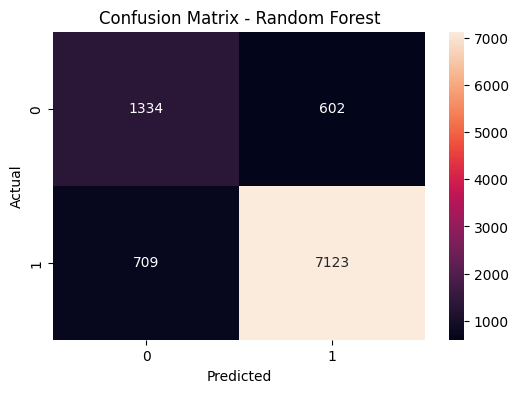

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm_rf, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score

lr_auc = roc_auc_score(y_test, logistic_model.predict_proba(X_test)[:,1])
rf_auc = roc_auc_score(y_test, rf_model.predict_proba(X_test)[:,1])

print("Logistic Regression ROC-AUC:", lr_auc)
print("Random Forest ROC-AUC:", rf_auc)

Logistic Regression ROC-AUC: 0.9370767588891515
Random Forest ROC-AUC: 0.9323641579048446


In [ ]:
import pandas as pd

rf_model_final = rf_model.named_steps['classifier']

feature_names = (
    rf_model.named_steps['preprocessor']
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model_final.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
0,num__buisness_year,0.574638
2,num__total_open_amount,0.410544
49,cat__cust_payment_terms_NAG2,0.001221
51,cat__cust_payment_terms_NAH4,0.000808
40,cat__cust_payment_terms_NAC6,0.000759
85,cat__cust_payment_terms_NAX2,0.000717
45,cat__cust_payment_terms_NAD1,0.000713
50,cat__cust_payment_terms_NAGD,0.000690
28,cat__cust_payment_terms_NA32,0.000688
66,cat__cust_payment_terms_NAU5,0.000583


In [ ]:
import joblib

joblib.dump(logistic_model, "invoice_payment_delay_model.pkl")

print("Model saved successfully")

Model saved successfully
